# Bias-Variance Analysis, Regularization and Dimensionality Reduction

Follow-up to `01_intrusion_detection.ipynb`. The models from the intrusion-detection pipeline are
examined more closely to answer one question: **is the remaining error mainly caused by bias or by variance?**

**Contents**
1. Background: bias, variance, underfitting and overfitting
2. Train/test gap for each model
3. Regularization: decision-tree depth sweep
4. Learning curves
5. PCA: how much can the feature space be reduced?
6. Stratified cross-validation
7. Label overlap: the irreducible error
8. Discussion

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
sys.path.append(os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (RANDOM_STATE, TARGET, NOMINAL_COLS, load_unsw_nb15,
                      numeric_feature_columns, encode_features, split_and_scale)

np.random.seed(RANDOM_STATE)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 13
sns.set_style('whitegrid')

FIG_DIR = os.path.abspath('../figures')
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=120, bbox_inches='tight')

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, learning_curve, train_test_split
from sklearn.tree import DecisionTreeClassifier

## 1. Background

**Bias** is how far the model's average prediction is from the truth. High bias means the model is too
simple to capture the underlying pattern (underfitting).

**Variance** is how much the model's predictions change between different training sets. High variance
means the model memorizes noise in the training data and generalizes poorly (overfitting).

| Symptom | Diagnosis |
|---|---|
| Train score low, test score low | High bias (underfitting) |
| Train score high, test score high | Good fit |
| Train score high, test score much lower | High variance (overfitting) |

**Remedies**
- High bias: a more expressive model, more or better features, less regularization
- High variance: regularization, fewer features, more training data, ensembles

In [2]:
df = load_unsw_nb15()
X_encoded, y_raw = encode_features(df)
X_train_s, X_test_s, y_train, y_test, _ = split_and_scale(X_encoded, y_raw)
classes = sorted(y_raw.unique())

print(f'{df.shape[0]:,} samples | {X_encoded.shape[1]} features after OHE')
print(f'Train: {X_train_s.shape[0]:,} | Test: {X_test_s.shape[0]:,}')
print(f'Classes ({len(classes)}): {classes}')

257,673 samples | 188 features after OHE
Train: 206,138 | Test: 51,535
Classes (10): ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


## 2. Train/test gap

A large gap between training and test macro F1 points to high variance; low scores on both point to high bias.

In [3]:
def clf_scores(name, model):
    model.fit(X_train_s, y_train)
    tr_pred = model.predict(X_train_s)
    te_pred = model.predict(X_test_s)
    tr_f1 = f1_score(y_train, tr_pred, average='macro', zero_division=0)
    te_f1 = f1_score(y_test, te_pred, average='macro', zero_division=0)
    return {
        'Model':     name,
        'Train Acc': accuracy_score(y_train, tr_pred),
        'Test Acc':  accuracy_score(y_test, te_pred),
        'Train F1':  tr_f1,
        'Test F1':   te_f1,
        'F1 Gap':    tr_f1 - te_f1,
    }

clf_defs = [
    ('Decision Tree (no limit)', DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ('Decision Tree (depth=10)', DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)),
    ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ('Logistic Regression (balanced)',
     LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
    ('Random Forest', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ('Random Forest (balanced)',
     RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
]

clf_results = []
for name, model in clf_defs:
    r = clf_scores(name, model)
    clf_results.append(r)
    print(f'{name:<32} Train F1={r["Train F1"]:.4f}  Test F1={r["Test F1"]:.4f}  Gap={r["F1 Gap"]:.4f}')

df_clf = pd.DataFrame(clf_results)
df_clf.round(4)

Decision Tree (no limit)         Train F1=0.7670  Test F1=0.5609  Gap=0.2061


Decision Tree (depth=10)         Train F1=0.4587  Test F1=0.4517  Gap=0.0070


Logistic Regression              Train F1=0.3435  Test F1=0.3449  Gap=-0.0013


Logistic Regression (balanced)   Train F1=0.3789  Test F1=0.3688  Gap=0.0101


Random Forest                    Train F1=0.7650  Test F1=0.5270  Gap=0.2380


Random Forest (balanced)         Train F1=0.7169  Test F1=0.5455  Gap=0.1714


,Model,Train Acc,Test Acc,Train F1,Test F1,F1 Gap
0,Decision Tree (no limit),0.9071,0.7978,0.7670,0.5609,0.2061
1,Decision Tree (depth=10),0.7783,0.7735,0.4587,0.4517,0.0070
2,Logistic Regression,0.7341,0.7364,0.3435,0.3449,-0.0013
3,Logistic Regression (balanced),0.6182,0.6114,0.3789,0.3688,0.0101
4,Random Forest,0.9071,0.8157,0.7650,0.5270,0.2380
5,Random Forest (balanced),0.8423,0.7554,0.7169,0.5455,0.1714


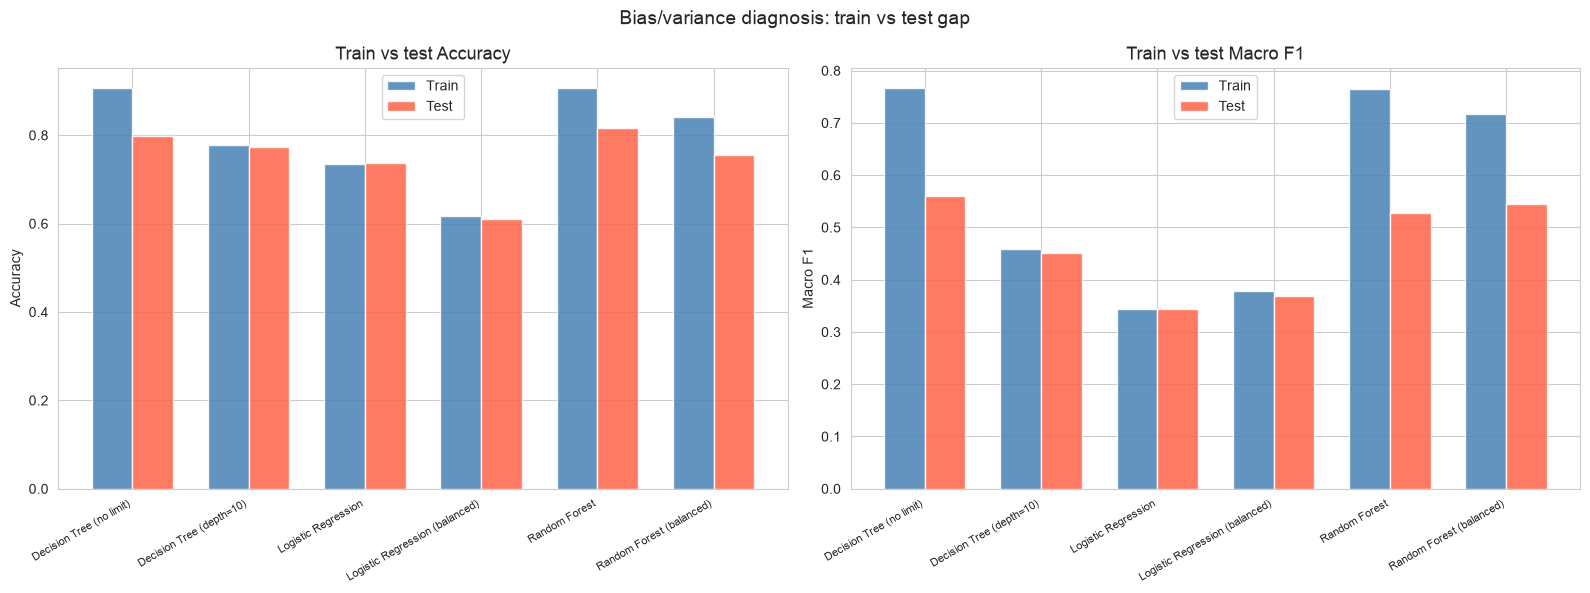

Macro F1 gap (train - test), large gap = high variance:
  Random Forest                    gap=0.2380  <-- high variance
  Decision Tree (no limit)         gap=0.2061  <-- high variance
  Random Forest (balanced)         gap=0.1714  <-- high variance
  Logistic Regression (balanced)   gap=0.0101
  Decision Tree (depth=10)         gap=0.0070
  Logistic Regression              gap=-0.0013


In [4]:
names = df_clf['Model']
x = np.arange(len(names))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metric, label in [(axes[0], 'Acc', 'Accuracy'), (axes[1], 'F1', 'Macro F1')]:
    ax.bar(x - w/2, df_clf[f'Train {metric}'], w, label='Train', color='steelblue', alpha=0.85)
    ax.bar(x + w/2, df_clf[f'Test {metric}'], w, label='Test', color='tomato', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=30, ha='right', fontsize=8)
    ax.set_ylabel(label)
    ax.set_title(f'Train vs test {label}')
    ax.legend()

plt.suptitle('Bias/variance diagnosis: train vs test gap', fontsize=14)
plt.tight_layout()
save('train_test_gap')
plt.show()

print('Macro F1 gap (train - test), large gap = high variance:')
for _, r in df_clf.sort_values('F1 Gap', ascending=False).iterrows():
    flag = '  <-- high variance' if r['F1 Gap'] > 0.10 else ''
    print(f"  {r['Model']:<32} gap={r['F1 Gap']:.4f}{flag}")

## 3. Regularization: decision-tree depth sweep

`max_depth` is the most direct capacity control for a decision tree. Shallow trees should underfit,
very deep trees should overfit.

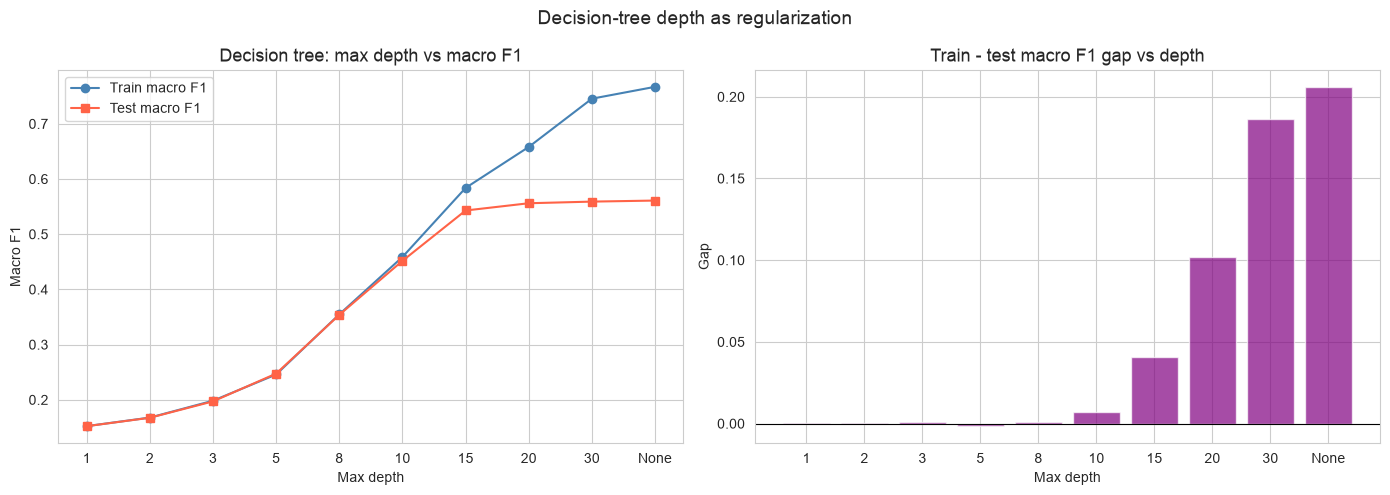

,max_depth,Train F1,Test F1,Gap
0,1,0.1523,0.1521,0.0001
1,2,0.1677,0.1674,0.0003
2,3,0.1983,0.1971,0.0012
3,5,0.2458,0.2474,-0.0016
4,8,0.3548,0.3539,0.0009
5,10,0.4587,0.4517,0.0070
6,15,0.5838,0.5429,0.0409
7,20,0.6581,0.5561,0.1020
8,30,0.7455,0.5590,0.1865
9,None,0.7670,0.5609,0.2061


In [5]:
depths = [1, 2, 3, 5, 8, 10, 15, 20, 30, None]
tr_f1s, te_f1s = [], []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train_s, y_train)
    tr_f1s.append(f1_score(y_train, dt.predict(X_train_s), average='macro', zero_division=0))
    te_f1s.append(f1_score(y_test, dt.predict(X_test_s), average='macro', zero_division=0))

depth_labels = [str(d) if d is not None else 'None' for d in depths]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(depth_labels, tr_f1s, 'o-', color='steelblue', label='Train macro F1')
axes[0].plot(depth_labels, te_f1s, 's-', color='tomato', label='Test macro F1')
axes[0].set_title('Decision tree: max depth vs macro F1')
axes[0].set_xlabel('Max depth')
axes[0].set_ylabel('Macro F1')
axes[0].legend()

gaps = [tr - te for tr, te in zip(tr_f1s, te_f1s)]
axes[1].bar(depth_labels, gaps, color='purple', alpha=0.7)
axes[1].set_title('Train - test macro F1 gap vs depth')
axes[1].set_xlabel('Max depth')
axes[1].set_ylabel('Gap')
axes[1].axhline(0, color='black', linewidth=0.8)

plt.suptitle('Decision-tree depth as regularization', fontsize=14)
plt.tight_layout()
save('depth_sweep')
plt.show()

pd.DataFrame({'max_depth': depth_labels, 'Train F1': tr_f1s, 'Test F1': te_f1s, 'Gap': gaps}).round(4)

## 4. Learning curves

Learning curves show how training and validation scores change as more data is added. A stratified
subsample of 20,000 training rows keeps the runtime manageable while preserving the class proportions.

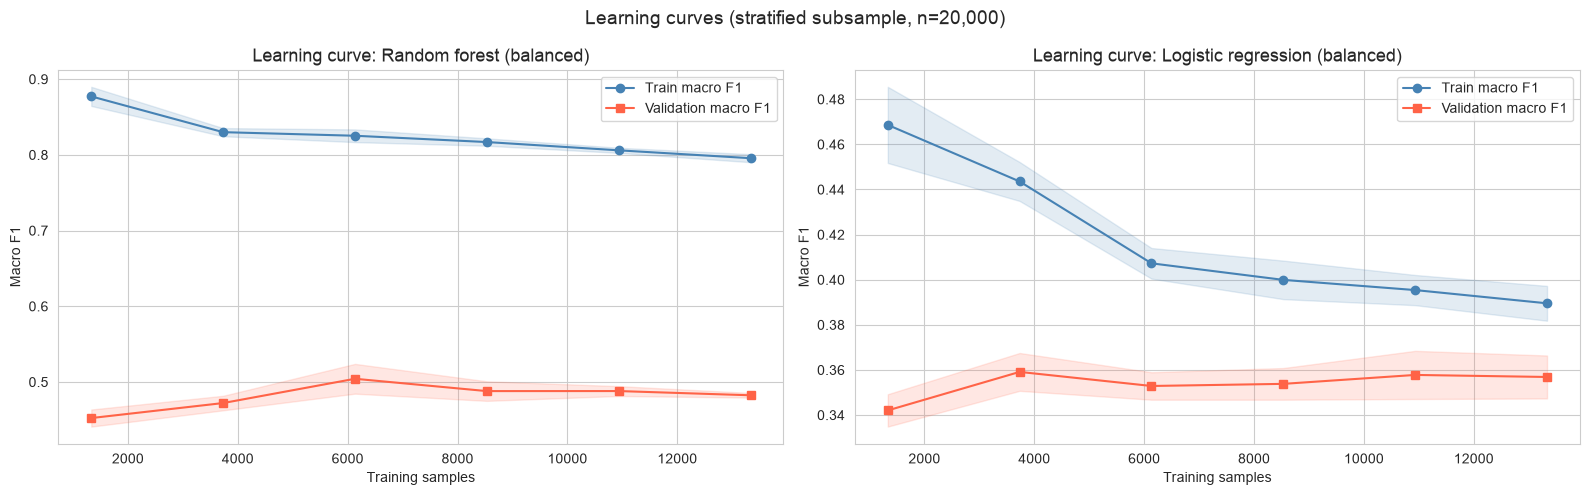

In [6]:
X_sub, _, y_sub, _ = train_test_split(X_train_s, y_train, train_size=20_000,
                                      stratify=y_train, random_state=RANDOM_STATE)
y_sub = np.asarray(y_sub)
skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, model, title in [
    (axes[0], RandomForestClassifier(n_estimators=50, class_weight='balanced',
                                     random_state=RANDOM_STATE, n_jobs=-1), 'Random forest (balanced)'),
    (axes[1], LogisticRegression(max_iter=500, class_weight='balanced',
                                 random_state=RANDOM_STATE), 'Logistic regression (balanced)'),
]:
    szs, tr_sc, va_sc = learning_curve(model, X_sub, y_sub, train_sizes=np.linspace(0.1, 1.0, 6),
                                       cv=skf3, scoring='f1_macro', n_jobs=-1)
    tr_m, tr_s = tr_sc.mean(axis=1), tr_sc.std(axis=1)
    va_m, va_s = va_sc.mean(axis=1), va_sc.std(axis=1)
    ax.plot(szs, tr_m, 'o-', color='steelblue', label='Train macro F1')
    ax.fill_between(szs, tr_m - tr_s, tr_m + tr_s, alpha=0.15, color='steelblue')
    ax.plot(szs, va_m, 's-', color='tomato', label='Validation macro F1')
    ax.fill_between(szs, va_m - va_s, va_m + va_s, alpha=0.15, color='tomato')
    ax.set_title(f'Learning curve: {title}')
    ax.set_xlabel('Training samples')
    ax.set_ylabel('Macro F1')
    ax.legend()

plt.suptitle('Learning curves (stratified subsample, n=20,000)', fontsize=14)
plt.tight_layout()
save('learning_curves')
plt.show()

## 5. PCA

One-hot encoding expands the feature space to ~190 columns, many of them rare protocol values.
How many principal components are needed, and what happens to performance when the space is reduced?

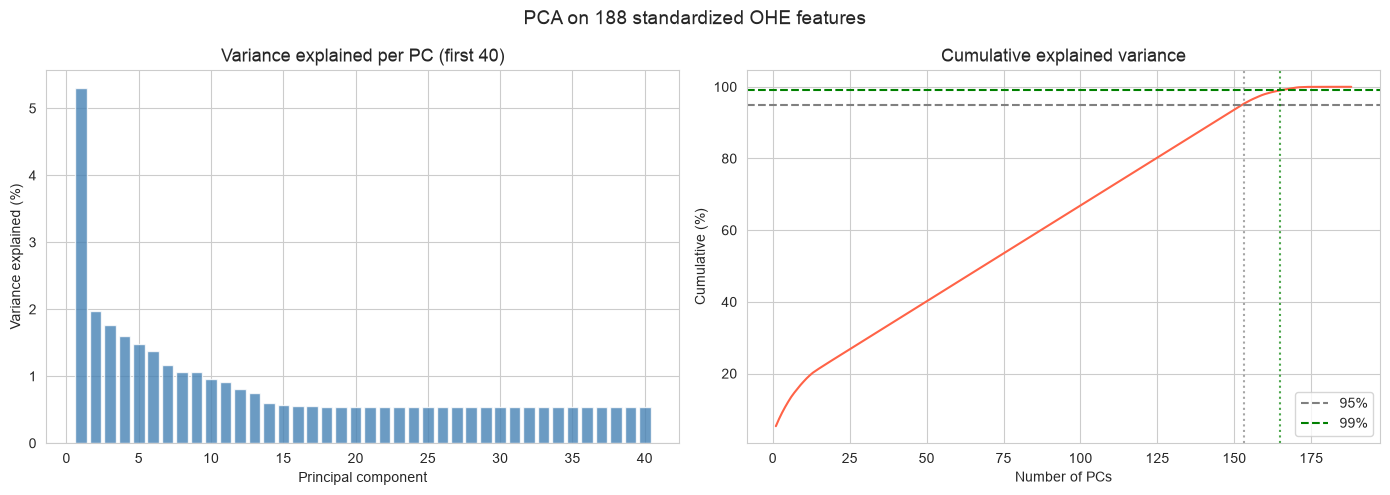

Original features:    188
PCs for 95% variance: 153
PCs for 99% variance: 165


In [7]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum_var >= 0.95)) + 1
n99 = int(np.argmax(cum_var >= 0.99)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 41), pca_full.explained_variance_ratio_[:40] * 100, color='steelblue', alpha=0.8)
axes[0].set_title('Variance explained per PC (first 40)')
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Variance explained (%)')

axes[1].plot(range(1, len(cum_var) + 1), cum_var * 100, color='tomato')
axes[1].axhline(95, color='gray', linestyle='--', label='95%')
axes[1].axhline(99, color='green', linestyle='--', label='99%')
axes[1].axvline(n95, color='gray', linestyle=':', alpha=0.7)
axes[1].axvline(n99, color='green', linestyle=':', alpha=0.7)
axes[1].set_title('Cumulative explained variance')
axes[1].set_xlabel('Number of PCs')
axes[1].set_ylabel('Cumulative (%)')
axes[1].legend()
plt.suptitle(f'PCA on {X_train_s.shape[1]} standardized OHE features', fontsize=14)
plt.tight_layout()
save('pca_variance')
plt.show()

print(f'Original features:    {X_train_s.shape[1]}')
print(f'PCs for 95% variance: {n95}')
print(f'PCs for 99% variance: {n99}')

In [8]:
pca_rows = []
for n_pcs, config in [(20, '20 PCs'), (50, '50 PCs'), (n95, '95% variance'),
                      (X_train_s.shape[1], f'All {X_train_s.shape[1]} features')]:
    if n_pcs < X_train_s.shape[1]:
        pca_k = PCA(n_components=n_pcs, random_state=RANDOM_STATE)
        Xtr_p = pca_k.fit_transform(X_train_s)
        Xte_p = pca_k.transform(X_test_s)
    else:
        Xtr_p, Xte_p = X_train_s, X_test_s
    rf_p = RandomForestClassifier(n_estimators=50, class_weight='balanced',
                                  random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr_p, y_train)
    te_pred = rf_p.predict(Xte_p)
    pca_rows.append({'Config': config, 'n_features': n_pcs,
                     'Test Acc': accuracy_score(y_test, te_pred),
                     'Test F1': f1_score(y_test, te_pred, average='macro', zero_division=0)})

pd.DataFrame(pca_rows).round(4)

,Config,n_features,Test Acc,Test F1
0,20 PCs,20,0.7304,0.5011
1,50 PCs,50,0.7271,0.4893
2,95% variance,153,0.7233,0.4783
3,All 188 features,188,0.7546,0.5448


## 6. Stratified cross-validation

3-fold stratified CV on a 15,000-row stratified subsample checks that the model ranking is not an
artefact of one particular train/test split. Stratification guarantees that the rarest class (Worms)
appears in every fold.

In [9]:
X_cv, _, y_cv, _ = train_test_split(X_train_s, y_train, train_size=15_000,
                                    stratify=y_train, random_state=RANDOM_STATE + 1)
y_cv = np.asarray(y_cv)
skf_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

cv_models = [
    ('Decision Tree (depth=10)', DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)),
    ('Logistic Regression', LogisticRegression(max_iter=500, random_state=RANDOM_STATE)),
    ('Logistic Regression (balanced)',
     LogisticRegression(max_iter=500, class_weight='balanced', random_state=RANDOM_STATE)),
    ('Random Forest', RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE, n_jobs=-1)),
    ('Random Forest (balanced)',
     RandomForestClassifier(n_estimators=50, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
]

cv_rows = []
for name, m in cv_models:
    sc = cross_val_score(m, X_cv, y_cv, cv=skf_cv, scoring='f1_macro', n_jobs=-1)
    cv_rows.append({'Model': name, 'CV mean F1': sc.mean(), 'CV std': sc.std(), 'CV min': sc.min()})

pd.DataFrame(cv_rows).sort_values('CV mean F1', ascending=False).round(4)

,Model,CV mean F1,CV std,CV min
4,Random Forest (balanced),0.4879,0.0161,0.4686
3,Random Forest,0.4474,0.0057,0.4397
0,Decision Tree (depth=10),0.4080,0.0032,0.4050
2,Logistic Regression (balanced),0.3747,0.0101,0.3605
1,Logistic Regression,0.3468,0.0026,0.3432


## 7. Label overlap: the irreducible error

An unrestricted decision tree should be able to memorize its training set almost perfectly, yet it only
reaches ~0.77 training macro F1 (section 2). That suggests that some rows cannot be separated at all.
The check below counts rows whose full feature vector also occurs with a *different* attack label.

Rows:                                    257,673
Distinct feature vectors:                138,842
Rows whose feature vector has >1 label:  48,485 (18.8%)


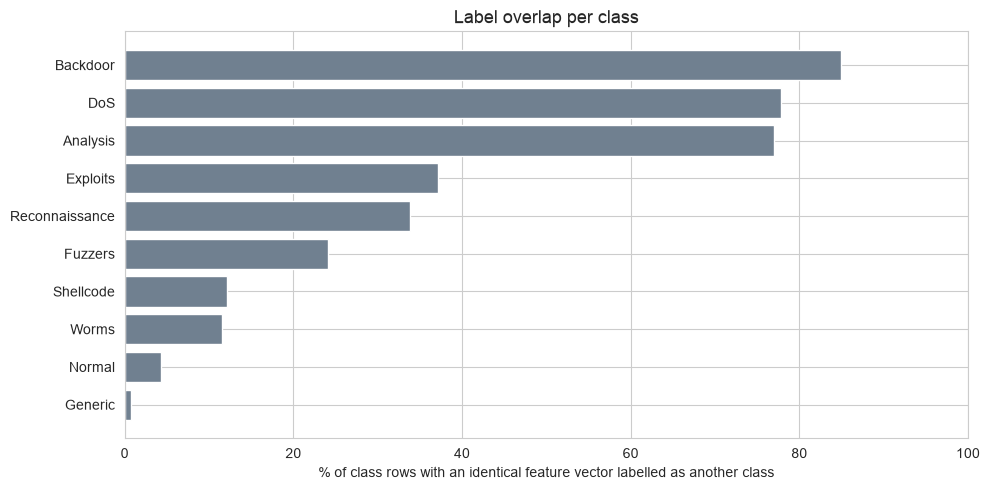

,% overlapping
attack_cat,
Generic,0.7
Normal,4.3
Worms,11.5
Shellcode,12.2
Fuzzers,24.1
Reconnaissance,33.8
Exploits,37.2
Analysis,77.0
DoS,77.8


In [10]:
feature_cols = [c for c in df.columns if c not in ('id', 'label', TARGET)]
labels_per_vector = df.groupby(feature_cols, observed=True)[TARGET].nunique()
conflicting = labels_per_vector[labels_per_vector > 1].index
in_conflict = df.set_index(feature_cols).index.isin(conflicting)

print(f'Rows:                                    {len(df):,}')
print(f'Distinct feature vectors:                {len(labels_per_vector):,}')
print(f'Rows whose feature vector has >1 label:  {in_conflict.sum():,} ({in_conflict.mean():.1%})')

overlap = (df.loc[in_conflict, TARGET].value_counts() / df[TARGET].value_counts()).fillna(0).sort_values()

plt.figure(figsize=(10, 5))
plt.barh(overlap.index, overlap.values * 100, color='slategray')
plt.xlabel('% of class rows with an identical feature vector labelled as another class')
plt.title('Label overlap per class')
plt.xlim(0, 100)
plt.tight_layout()
save('label_overlap')
plt.show()

(overlap * 100).round(1).rename('% overlapping').to_frame()

## 8. Discussion

### Is the main challenge bias or variance?

**Both, depending on the model, but the ceiling is set by the data.**

- **Tree-based models (unrestricted tree, random forest) have high variance.** Their training macro F1 is
  0.72-0.77 while test macro F1 is 0.53-0.56, a gap of 0.17-0.24. The random-forest learning curve keeps a
  large, stable gap as more data is added, and the validation curve flattens out around 0.48-0.50.
- **Logistic regression has high bias.** Training and test scores are almost identical (~0.34-0.38), and the
  learning curves converge at a low level. Linear decision boundaries in the one-hot feature space are not
  expressive enough to separate ten classes. More data will not help; a more flexible model does.
- **The class-imbalance bias** (models ignoring rare classes) is a separate effect, and is handled with class
  weights or SMOTE in notebook 01.

### Regularization

The depth sweep shows the classic picture. Up to depth 10 the train and test curves are on top of each other
and both are low (underfitting). From depth 15 the gap opens (0.04 at depth 15, 0.10 at depth 20, 0.21 without
a limit), while test macro F1 only goes from 0.543 to 0.561. **Depth 15-20 is a reasonable trade-off**: almost
all of the attainable test performance with a clearly smaller generalization gap than a fully grown tree.
Depth 10, which looks "safe" by gap, is actually too shallow and gives up ~0.10 macro F1.

### Dimensionality reduction

PCA is **not** useful here. 153 of 188 components are needed to keep 95% of the variance, because the one-hot
columns are close to orthogonal and carry little redundant information. Training the forest on principal
components also *lowers* macro F1 (0.48-0.50 vs 0.545 on the original features): trees work best with
axis-aligned, interpretable splits such as "is this TCP?", and PCA mixes all features into dense
linear combinations that destroy those splits.

### Cross-validation

Stratified 3-fold CV on a subsample gives the same ranking as the full train/test split (balanced random
forest > random forest > depth-10 tree > logistic regression), with standard deviations of 0.003-0.016.
Absolute scores are lower because the subsample contains only ~10 Worms rows, but the conclusions do not
depend on one particular split. Stratification is essential for that: without it, a fold could easily end
up with no Worms samples at all.

### The real limit: overlapping labels

About **19% of all rows** share their exact feature vector with a row from a different class. For `Backdoor`
(~85%), `DoS` (~78%) and `Analysis` (~77%) the majority of rows are indistinguishable from other classes,
which is exactly why these three classes have the lowest F1 for every model. This is irreducible (Bayes) error:
no amount of tuning, regularization or extra data can separate identical inputs.

**Conclusion:** after reasonable regularization and imbalance handling, the remaining error is dominated
neither by bias nor variance, but by the information content of the flow-level features. Further gains would
need richer features (payload- or time-window-based), or merging attack categories that the current features
cannot tell apart, rather than more model tuning.